### EXERCISE 1 — COLOR-MAGNITUDE DIAGRAM OF NGC 6397 WITH GAIA DR3 AND IDENTIFICATION OF THE MAIN-SEQUENCE TURN-OFF

1. Query the Gaia catalog for stars in NGC 6397
2. Plot the distribution on the sky
3. Color-Magnitude Diagram
4. Field star removal based on proper motion

SCIENTIFIC SCENARIO: a globular cluster is a nearly coeval and chemically homogeneous stellar population: its CMD is the "snapshot" of a single isochrone at the cluster's distance. Proper motions allow us to remove almost all
foreground/background field stars and obtain a clean CMD even for clusters projected onto crowded fields like NGC 6397.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from astroquery.vizier import Vizier
from astropy.table import Table
import os
import astropy.units as u
from astropy.io import fits

#### TASK 1 - QUERY THE GAIA CATALOG FOR STARS IN NGC 6397

Perform a query by object name, specifying the search radius, catalog name, and output columns.
Check the number of objects returned and save the table to a FITS file.

In [2]:
def query_cluster(cluster_name, search_radius, columns, catalog="I/355/gaiadr3", row_limit=-1):
    """
    Query for an object from a specific catalog(s) and return the results as an astropy Table.

    Parameters:
    cluster_name (str): Name of the cluster to query.
    search_radius (str): Search radius around the cluster name (e.g., '0.5 deg').
    columns (list): List of columns to retrieve from the catalog.
    catalog (str): Catalog to query (default is "I/355/gaiadr3").
    row_limit (int): Maximum number of rows to return (-1 for no limit).

    Returns:
    astropy.table.Table: Table containing the queried data.
    """

    # Create the Vizier query object.
    v = Vizier(columns=columns, catalog=catalog, row_limit=row_limit)

    # Execute the query.
    # Vizier returns a TableList (a list of Tables), not a single Table.
    result = v.query_object(cluster_name, radius=search_radius)

    # Check if the query returned no tables
    if len(result) == 0:
        raise ValueError(f"No results found for {cluster_name} in catalog {catalog}.")

    # Extract the first Table from the TableList.
    # This convert the output from TableList to Table.
    return result[0]

In [15]:
# --- Task 1: Gaia DR3 cone search around NGC 6397 ---

# Central coordinates of the cluster
cluster_name = "NGC 6397"
search_radius = 400 * u.arcsec

# Columns to retrieve from the Gaia catalog
# RA_ICRS: Right Ascension (ICRS)
# DE_ICRS: Declination (ICRS)
# parallax: Parallax in milliarcseconds
# Gmag: Gaia G-band magnitude
# BPmag: Gaia Blue photometric magnitude
# RPmag: Gaia Red photometric magnitude
# pmRA: Proper motion in Right Ascension (mas/yr)
# pmDE: Proper motion in Declination (mas/yr)
# PM: Total proper motion (mas/yr)
# Plx: Parallax (mas)
columns = ["RA_ICRS", "DE_ICRS", "parallax", "Gmag", "BPmag", "RPmag", "pmRA", "pmDE", "PM", "Plx"]

In [17]:
file_name = "ngc6397_gaia_data.fits"

# Call query_cluster, save the result to a FITS file if it does not exist,
# and load it into catalog_data.

# If the FITS file does not exist, perform the query and save the data.
# Otherwise, directly load the existing FITS file.
if not os.path.exists(file_name):

    # Query Gaia DR3 around the selected cluster.
    # query_cluster now returns an astropy Table.
    catalog_data = query_cluster(cluster_name, search_radius, columns)
    
    # Save the table into a FITS file for future use.
    catalog_data.write(file_name, format='fits', overwrite=True)

# Load the catalog data from the FITS file.
# This works whether the file was just created or already existed.
else:
    catalog_data = Table.read(file_name, format='fits')

In [18]:
# NUMBER OF OBJECTS
# We expect ~ 30 000 stars from the I/355/gaiadr3 catalog with a search radius of 400".

print("Number of stars retrieved:", len(catalog_data))

Number of stars retrieved: 28919


In [19]:
# Query for the number of available Vizier catalogs at the cluster position.

all_catalogs = Vizier(row_limit=1)
catalogs = all_catalogs.query_region(cluster_name, radius=search_radius)

In [20]:
print("The number of catalogs returned:", len(catalogs))

The number of catalogs returned: 507


- What changes when extending or reducing the search radius?
  Increasing/decreasing the search radius, the number of stars and catalogs increases/decreases.

- Are there other catalogs from which the relevant information for the selected object can be retrieved?
  Yes, there are other catalogs.


#### TASK 2 - PLOT THE DISTRIBUTION ON THE SKY

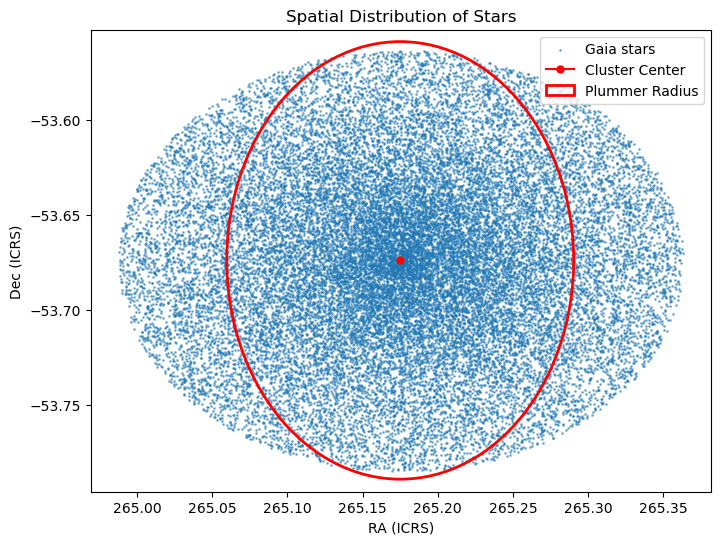

In [22]:
# Plot the spatial distribution of stars in RA and Dec.
# Mark the cluster center and its Plummer radius from the literature.

# Extract RA and Dec from the catalog data
ra = catalog_data['RA_ICRS']
dec = catalog_data['DE_ICRS']

# Create the plot
plt.figure(figsize=(8, 6))

# Plot the stars
plt.scatter(ra, dec, s=1, alpha=0.5, label='Gaia stars')

# Values for the cluster center and Plummer radius from the literature
cluster_center_ra = 265.175  # RA in degrees
cluster_center_dec = -53.674  # Dec in degrees
plummer_radius = 6.92 / 60  # Plummer radius in degrees (6.92 arcmin)

# Mark the cluster centre
plt.plot(cluster_center_ra, cluster_center_dec, color='red', marker='o', ms=5, label='Cluster Center')

# Mark the Plummer radius as a circle
circle = plt.Circle((cluster_center_ra, cluster_center_dec), plummer_radius, color='red', fill=False, label='Plummer Radius')
plt.gca().add_artist(circle)
circle.set_linewidth(2)
circle.set_zorder(10)

plt.xlabel('RA (ICRS)')
plt.ylabel('Dec (ICRS)')
plt.title('Spatial Distribution of Stars')

plt.legend()

plt.show()

- How are the queried stars distributed on the sky?
Queried stars are distributed in a roughly circular pattern around the cluster center, with a higher density of stars near
the center and decreasing density as we move outward.

- How does the plot compare with the estimated position of the cluster and its Plummer radius, taking these values from the literature (Vasiliev, E. & Baumgardt, H. 2021, MNRAS 505, 5978)?
The estimated position of the cluster corresponds with the center of the distribution of stars.
The Plummer radius encompasses a significant portion of the stars, indicating that many of the stars are likely
members of the cluster; however, the distribution of stars extends beyond the Plummer radius.

#### TASK 3 - COLOR-MAGNITUDE DIAGRAM

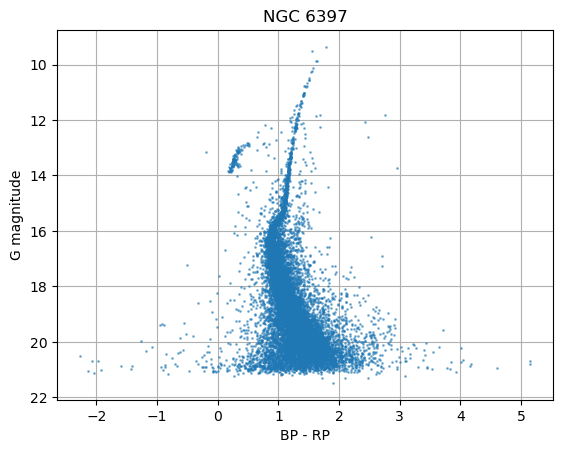

In [24]:
# Plot the color-magnitude diagram (BP - RP vs G magnitude)

# Calculate the color index (BP - RP) and extract the G magnitude from the catalog data
bp_rp = catalog_data["BPmag"] - catalog_data["RPmag"]
g_mag = catalog_data["Gmag"]

# Create the color-magnitude diagram
plt.plot(bp_rp, g_mag, "o", ms=1, alpha=0.5)

plt.xlabel("BP - RP")
plt.ylabel("G magnitude")
plt.title(cluster_name)
plt.gca().invert_yaxis()

plt.grid(True)

plt.show()

- How does the color-magnitude diagram compare with Fig. 4 of Vasiliev, E. & Baumgardt, H. 2021, MNRAS 505, 5978?
This CMD shows a main sequence with higher values of magnitude (G = 10 - 21) and a base with a larger spread in color, approx
from 0.5 to 2.5. Furthermore, the main sequence is more populated in the lower part of the diagram, while in the upper
part there are fewer stars. The turn-off point is visible at around G=16 and BP-RP=1. Finally, the red giant branch is
also visible at around G=13 and BP-RP=0.5 and is quite vertical, with a small spread in color.
On the other hand, the CMD in Fig. 4 of Babusiaux et al. (2018) shows a main sequence with lower values of magnitude
(G = -2 - 8) and a base with a smaller spread in color, approx from 0.6 to 1.2. There is less difference between the stellar
densities in the upper and lower part of the diagram. The turn-off point is visible at around G=4 and BP-RP=0.9. Finally,
the red giant branch is alsovisible at around G=0 and BP-RP=1 and is quite horizontal, with a bigger spread in color.

- What problem affects the resulting catalog? What are the physical and methodological reasons behind it?
The main problem affecting the resulting catalog is the contamination from field stars, which are stars that are not
physically associated with the cluster but are located along the same line of sight. This contamination can lead to an
inaccurate representation of the cluster's stellar population in the color-magnitude diagram.

#### TASK 4 - FIELD STAR REMOVAL BASED ON PROPER MOTION

Use the catalog information to decontaminate the sample.

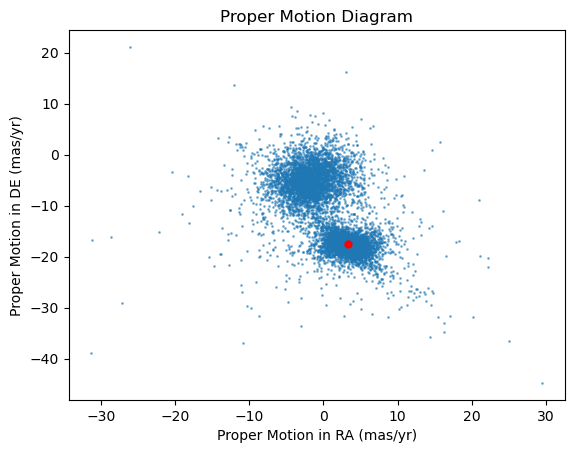

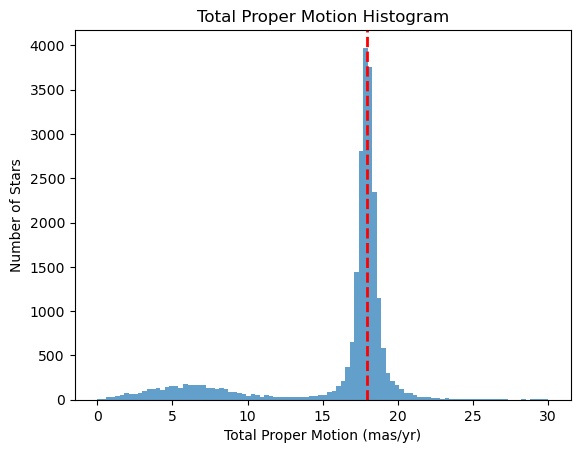

In [26]:
# Plot the proper motion diagram (pmRA vs pmDE) and the total proper motion histogram
# Mark the literature values for the cluster mean proper motion

plt.plot(catalog_data['pmRA'], catalog_data['pmDE'], 'o', ms=1, alpha=0.5)
plt.xlabel('Proper Motion in RA (mas/yr)')
plt.ylabel('Proper Motion in DE (mas/yr)')
plt.title('Proper Motion Diagram')

pmra_mean = 3.29
pmdec_mean = -17.59
plt.plot(pmra_mean, pmdec_mean, color='red', marker='o', ms=5)

plt.show()

# total_pm = sqrt(pmRA^2 + pmDE^2) (mas/yr)
plt.hist(catalog_data['PM'], range=(0, 30), bins=100, alpha=0.7)
plt.xlabel('Total Proper Motion (mas/yr)')
plt.ylabel('Number of Stars')
plt.title('Total Proper Motion Histogram')

literature_pm = 17.96 
plt.axvline(literature_pm, color='red', linestyle='--', linewidth=2)

plt.show()


In [27]:
# Proposed PM cut for cluster membership selection
pm_cuts = [12, 15, 17]

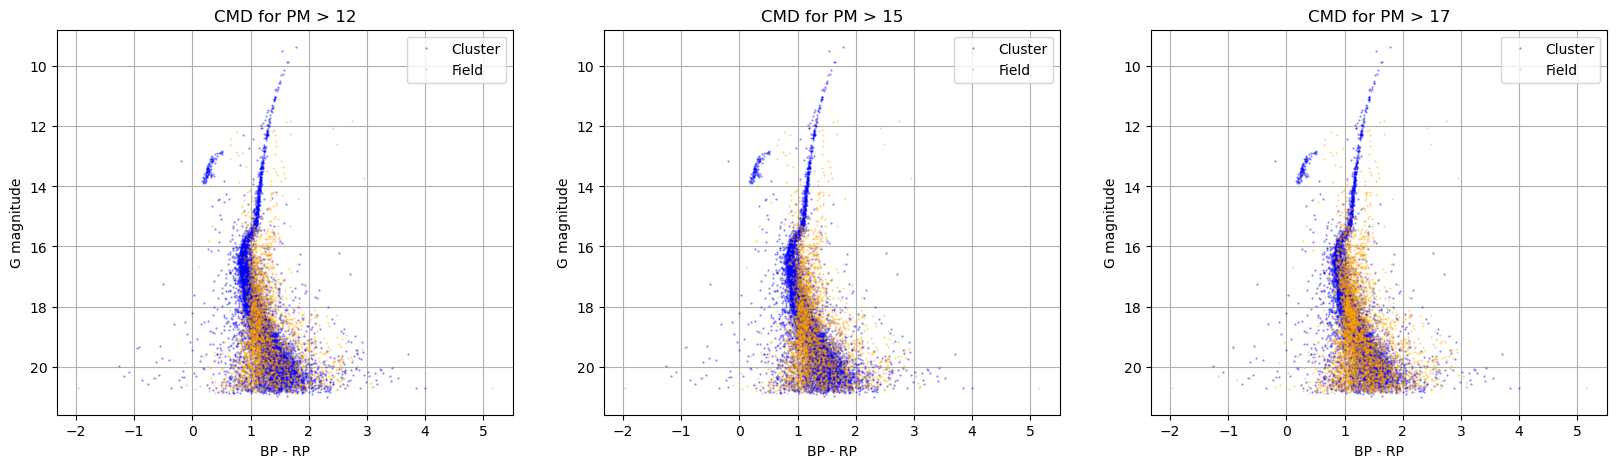

In [28]:
figure, ax = plt.subplots(1, len(pm_cuts), figsize=(20, 5))

# Create a CMD for different proper motion cuts
for i, pm_cut in enumerate(pm_cuts):
    
    # - Split catalog_data into cluster_stars (PM > pm_cut) and field_stars (PM <= pm_cut).
    # - Plot the CMD for each group.
    # - Set axis labels, title, grid, and legend.

    cluster_stars = catalog_data[catalog_data["PM"] > pm_cut]
    field_stars = catalog_data[catalog_data["PM"] <= pm_cut]
    
    ax[i].plot(cluster_stars['BPmag'] - cluster_stars['RPmag'], cluster_stars['Gmag'],
                ".", ms=1, alpha=0.5, color="blue", label="Cluster")

    ax[i].plot(field_stars['BPmag'] - field_stars['RPmag'], field_stars['Gmag'],
                ".", ms=1, alpha=0.5, color="orange", label="Field")

    ax[i].set_xlabel('BP - RP')
    ax[i].set_ylabel('G magnitude')
    ax[i].set_title(f'CMD for PM > {pm_cut}')
    ax[i].grid(True)
    ax[i].invert_yaxis()
    ax[i].legend()

- Given the previous plots, why is decontamination essential?
It's essential because the presence of field stars can obscure the true properties of the cluster's stellar population,
leading to incorrect conclusions about its age, metallicity, and evolutionary state.

- What does the proper motion method consist of? On which observables and which physical process is it based? What are its strengths and limitations?
The proper motion method involves selecting stars based on their proper motion values, which are the apparent motions of
stars across the sky. With this method, we can identify stars that are likely members of the cluster based on their similar
proper motion vectors, while field stars will have a wider range of proper motion values.
It is based on the variation of the angular position of the stars over time (i.e. variation of right ascension and
declination), which allows us to measure their proper motion.
The physical process underlying this method is the kinematics of stars, which describes their motion through space due to
gravitational interactions.

Strengths: It can effectively separate cluster members from field stars based only on their kinematic properties.
            It improves the color-magnitude diagram. It's a purely geometric methode.

Limitations: It may not be effective if the proper motion distributions of cluster and field stars overlap significantly.
            In highly crowded stellar fields, the detection and accurate measurement of stellar positions become more
            challenging. It requires very precise observations and repeated over time. It's sensible to sistematic errors.

- Apply the proper motion method iteratively and assess the robustness of the results for various cut values.How do the previous plots change as the proper motion cut varies?
Increasing the PM cut value causes the selection to become more stringent, including only stars with higher proper motions.
As a result, fewer field stars contaminate the cluster CMD, but some genuine cluster members with lower proper motions may
also be excluded.

- Optional: can automated methods be applied to separate the two populations?
Automated methods can be used to separate the two populations by clustering stars in the proper motion space.
Algorithms such as Gaussian Mixture Models or density-based clustering can identify cluster members based on their
kinematic properties, reducing the subjectivity of manual PM cuts.

#### OPTIONAL QUESTION

Proposed method: Gaussian Mixture Model (GMM) to separate cluster members from field stars based on their proper motion distribution. The GMM is a probabilistic model that assumes the data is generated from a mixture of several Gaussian distributions, each representing a different population (e.g., cluster members and field stars). The GMM can be fitted to the proper motion data, and the resulting components can be used to classify stars as likely cluster members or field stars. This method allows for a more sophisticated separation of populations compared to simple PM cuts.

Stelle iniziali: 28919
Stelle usate nel GMM: 17469
Centri delle componenti GMM:
[[  3.24713771 -17.65278775]
 [ -0.09676828  -9.317947  ]]


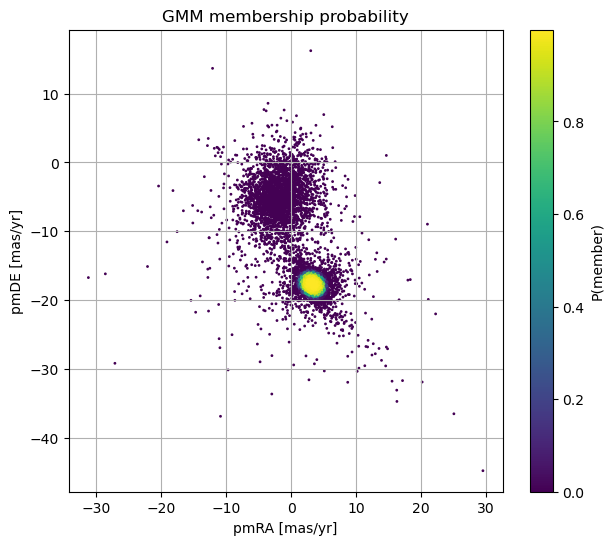

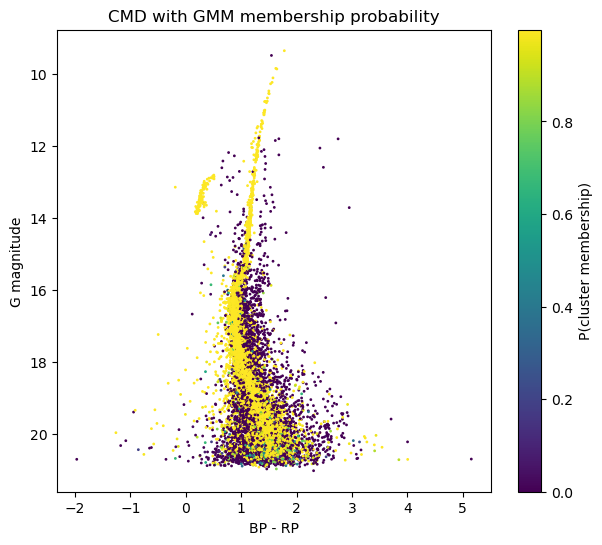

In [ ]:
from sklearn.mixture import GaussianMixture

# 1) Gaia data cleaning

# Necessary columns: pmRA, pmDE, BPmag, RPmag, Gmag
mask = (
    np.isfinite(catalog_data["pmRA"]) &
    np.isfinite(catalog_data["pmDE"]) &
    np.isfinite(catalog_data["BPmag"]) &
    np.isfinite(catalog_data["RPmag"]) &
    np.isfinite(catalog_data["Gmag"])
)

catalog_clean = catalog_data[mask]

print("Stelle iniziali:", len(catalog_data))
print("Stelle usate nel GMM:", len(catalog_clean))


# 2) Construction of the feature matrix X

X = np.column_stack([catalog_clean["pmRA"], catalog_clean["pmDE"]])


# 3) Fit Gaussian Mixture Model

gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=42)
gmm.fit(X)


# 4) Probability of membership for each star

prob = gmm.predict_proba(X)

# Look at the centers of the two populations
print("Centri delle componenti GMM:")
print(gmm.means_)


# 5) Identification of the cluster component

cluster_component = 0
P_member = prob[:, cluster_component]

# Add the membership probability to the table
catalog_clean["P_member"] = P_member


# 6) Plot of the proper motion plane

plt.figure(figsize=(7,6))

plt.scatter(catalog_clean["pmRA"], catalog_clean["pmDE"], c=P_member, s=1, cmap="viridis")

plt.xlabel("pmRA [mas/yr]")
plt.ylabel("pmDE [mas/yr]")
plt.title("GMM membership probability")
plt.colorbar(label="P(member)")
plt.grid()

plt.show()


# 7) Plot CMD with membership probability

plt.figure(figsize=(7,6))

plt.scatter(catalog_clean["BPmag"] - catalog_clean["RPmag"], catalog_clean["Gmag"], c=P_member, s=1, cmap="viridis")

plt.gca().invert_yaxis()
plt.xlabel("BP - RP")
plt.ylabel("G magnitude")
plt.colorbar(label="P(cluster membership)")
plt.title("CMD with GMM membership probability")

plt.show()